# 🚀 Practice Day 55

**📅 Date:** 2026-11-06  
📁 Category: Phase 1 · Pandas 기초 (Round 5/5)

---
# 🎯 Today's Goal
*What am I trying to solve today?*

- Practice core Pandas fundamentals — filtering, sorting, groupby, and aggregation — on a simple single-table dataset
  (기본적인 Pandas 기초 — 필터링, 정렬, groupby, 집계 — 를 단순한 단일 테이블 데이터로 연습하기)
- Find the shoe store's best sellers, which category earns the most, and how revenue varies by day of week
  (신발 매장의 베스트셀러 상품, 가장 매출이 높은 카테고리, 요일별 매출 변화를 파악하기)

---
# 📂 Dataset

**Dataset Name:** Stride & Sole — Daily Product Sales / 일별 상품 판매 데이터

**Source:** Synthetically generated for practice / 실습을 위해 코드로 생성한 가상 데이터

**Description:** 30 days (April 2024) of daily sales for 7 shoe products across 5 categories (Running, Casual, Formal, Sandals, Boots) — 210 rows total (7 products × 30 days), single table. Revenue is in USD. Clean — no missing values or duplicates.
(2024년 4월 30일간 7개 신발 상품(Running/Casual/Formal/Sandals/Boots 5개 카테고리)의 일별 판매 데이터입니다(단일 테이블, 210행 = 7상품×30일). 매출은 USD 기준이며 결측치·중복 없이 깨끗합니다.)

## Dataset Preview

In [29]:
# Dataset Preview
import numpy as np
import pandas as pd

np.random.seed(42)
rng = np.random.default_rng(42)

# --- Generate a month of daily sales for 7 shoe products (prices in USD) ---
products = {
    'Trailblazer Runner': ('Running', 68),
    'AirCloud Sneaker': ('Running', 72),
    'Weekend Loafer': ('Casual', 55),
    'Classic Canvas': ('Casual', 38),
    'Oxford Derby': ('Formal', 95),
    'Summer Slide': ('Sandals', 25),
    'Ankle Chelsea Boot': ('Boots', 88),
}
base_qty = {
    'Trailblazer Runner': 12, 'AirCloud Sneaker': 10, 'Weekend Loafer': 9, 'Classic Canvas': 14,
    'Oxford Derby': 5, 'Summer Slide': 11, 'Ankle Chelsea Boot': 6
}

dates = pd.date_range('2024-04-01', periods=30, freq='D')

rows = []
for product, (category, price) in products.items():
    for d in dates:
        noise = rng.normal(1.0, 0.20)
        qty = max(0, int(round(base_qty[product] * noise)))
        revenue = qty * price  # USD
        rows.append({'date': d, 'product': product, 'category': category,
                     'quantity_sold': qty, 'revenue': revenue})

df = pd.DataFrame(rows).sort_values(['date', 'product']).reset_index(drop=True)

df.head(10)


,date,product,category,quantity_sold,revenue
0,2024-04-01,AirCloud Sneaker,Running,14,1008
1,2024-04-01,Ankle Chelsea Boot,Boots,8,704
2,2024-04-01,Classic Canvas,Casual,16,608
3,2024-04-01,Oxford Derby,Formal,4,380
4,2024-04-01,Summer Slide,Sandals,11,275
5,2024-04-01,Trailblazer Runner,Running,13,884
6,2024-04-01,Weekend Loafer,Casual,6,330
7,2024-04-02,AirCloud Sneaker,Running,9,648
8,2024-04-02,Ankle Chelsea Boot,Boots,6,528
9,2024-04-02,Classic Canvas,Casual,14,532


## Dataset Information

In [30]:
# Dataset Information
df.info()
print("\nShape:", df.shape)
df.describe(include='all')


<class 'pandas.DataFrame'>
RangeIndex: 210 entries, 0 to 209
Data columns (total 5 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   date           210 non-null    datetime64[us]
 1   product        210 non-null    str           
 2   category       210 non-null    str           
 3   quantity_sold  210 non-null    int64         
 4   revenue        210 non-null    int64         
dtypes: datetime64[us](1), int64(2), str(2)
memory usage: 8.3 KB

Shape: (210, 5)


,date,product,category,quantity_sold,revenue
count,210,210,210,210.000000,210.000000
unique,NaN,7,5,NaN,NaN
top,NaN,AirCloud Sneaker,Running,NaN,NaN
freq,NaN,30,60,NaN,NaN
mean,2024-04-15 12:00:00,NaN,NaN,9.428571,544.776190
min,2024-04-01 00:00:00,NaN,NaN,3.000000,175.000000
25%,2024-04-08 00:00:00,NaN,NaN,7.000000,404.500000
50%,2024-04-15 12:00:00,NaN,NaN,10.000000,528.000000
75%,2024-04-23 00:00:00,NaN,NaN,12.000000,680.000000
max,2024-04-30 00:00:00,NaN,NaN,18.000000,1020.000000


---
# ❓ Business Questions

1. **(Analysis)** Which product sold the most units overall, and which sold the least?
   (전체 기간 기준 가장 많이/적게 팔린 상품은?)
2. **(Analysis)** Which category generated the most total revenue, and which the least?
   (가장 매출이 높은/낮은 카테고리는?)
3. **(Analysis)** How does average daily revenue vary by day of week?
   (요일별 평균 일일 매출은 어떻게 다른가?)
4. **(Visualization)** Compare total units sold across all 7 products.
   (7개 상품의 총 판매량을 비교하면?)
5. **(Visualization)** Show how daily revenue moves across the month.
   (한 달간 일별 매출은 어떻게 변화하는가?)

---
# 🔍 Data Cleaning Check


In [31]:
# Data Cleaning Check — inspect only. Fixes are in Q1–Q3.
# (확인만. 수정은 Q1~Q3)

print("Missing values")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nDtypes")
print(df.dtypes)

print("\nColumn names")
print(df.columns.tolist())

obj_cols = df.select_dtypes(include=["object", "string"]).columns
print("\nText columns — unique counts")
print(df[obj_cols].nunique())


Missing values
date             0
product          0
category         0
quantity_sold    0
revenue          0
dtype: int64

Duplicate rows: 0

Dtypes
date             datetime64[us]
product                     str
category                    str
quantity_sold             int64
revenue                   int64
dtype: object

Column names
['date', 'product', 'category', 'quantity_sold', 'revenue']

Text columns — unique counts
product     7
category    5
dtype: int64


---
# 📊 Analysis

## Question 1

**Question:** Which product sold the most units overall, and which sold the least? (가장 많이/적게 팔린 상품은?)

**Result:**  
Classic Canvas sold the most with **395** units, and Oxford Derby sold the least with **149** units.  
(가장 많이 팔린 상품은 Classic Canvas **395**개, 가장 적게 팔린 상품은 Oxford Derby **149**개입니다.)  

**Insight:**  
Classic Canvas sold **246** more units than Oxford Derby, so unit volume differs a lot across the 7 products.  
(Classic Canvas는 Oxford Derby보다 **246**개 더 팔려서, 7개 상품 간 판매량 차이가 큽니다.)

In [32]:
# Question 1: total quantity sold by product (most / least)
sold_quantity_by_product = df.groupby('product')['quantity_sold'].sum().sort_values(ascending=False)

sold_quantity_by_product

product
Classic Canvas        395
Trailblazer Runner    362
Summer Slide          324
AirCloud Sneaker      302
Weekend Loafer        262
Ankle Chelsea Boot    186
Oxford Derby          149
Name: quantity_sold, dtype: int64

## Question 2

**Question:** Which category generated the most total revenue, and which the least? (가장 매출이 높은/낮은 카테고리는?)

**Result:**  
Running earned the most with **$46,360**, and Sandals earned the least with **$8,100**.  
(Running이 **$46,360**으로 매출이 가장 높고, Sandals가 **$8,100**으로 가장 낮습니다.)  

**Insight:**  
Running earned **$38,260** more than Sandals. Casual is second with **$29,420**.  
(Running은 Sandals보다 **$38,260** 더 벌었고, 2위는 Casual로 **$29,420**입니다.)

In [33]:
# Question 2: total revenue by category (highest / lowest)
df.groupby('category')['revenue'].sum().sort_values(ascending=False)

category
Running    46360
Casual     29420
Boots      16368
Formal     14155
Sandals     8100
Name: revenue, dtype: int64

## Question 3

**Question:** How does average daily revenue vary by day of week? (요일별 평균 매출 변화는?)

**Result:**  
Sunday has the highest average daily revenue at **$4,012.25**, and Tuesday has the lowest at **$3,628.80**.  
(일요일의 평균 일일 매출이 **$4,012.25**로 가장 높고, 화요일이 **$3,628.80**으로 가장 낮습니다.)  

**Insight:**  
The gap between Sunday and Tuesday is **$383.45**, and revenue moves up and down only slightly across weekdays.  
(일요일과 화요일의 차이는 **$383.45**이며, 요일별 매출은 크게 차이 나지 않고 조금씩 오르내립니다.)

In [34]:
# Question 3: average daily revenue by day of week
daily_total = df.groupby('date', as_index=False)['revenue'].sum()
day_rev = (
    daily_total.groupby(daily_total['date'].dt.day_name())['revenue']
    .mean()
    .reindex(['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday'])
    .reset_index()
)

day_rev['prev_day_rev'] = day_rev['revenue'].shift(1)
day_rev['change'] = day_rev['revenue'] - day_rev['prev_day_rev']
day_rev['pct_change'] = (day_rev['change'] / day_rev['prev_day_rev'] * 100).round(2)
day_rev

,date,revenue,prev_day_rev,change,pct_change
0,Monday,3804.60,NaN,NaN,NaN
1,Tuesday,3628.80,3804.60,-175.80,-4.62
2,Wednesday,3758.25,3628.80,129.45,3.57
3,Thursday,3776.25,3758.25,18.00,0.48
4,Friday,3913.75,3776.25,137.50,3.64
5,Saturday,3848.50,3913.75,-65.25,-1.67
6,Sunday,4012.25,3848.50,163.75,4.25


---
# 📈 Visualization

**Chart 1:** Bar chart — total units sold by product (막대그래프: 상품별 총 판매량)

*Interpretation:*  
Classic Canvas has the longest bar at **395** units and Oxford Derby the shortest at **149**.  
(Classic Canvas의 막대가 **395**개로 가장 길고 Oxford Derby가 **149**개로 가장 짧습니다.)  

---

**Chart 2:** Line chart — daily revenue trend (선그래프: 일별 매출 추이)

*Interpretation:*  
Daily revenue moves up and down all month, with a high of **$4,370** on Apr 19 and a low of **$3,245** on Apr 25.  
(일별 매출은 한 달 내내 오르내리며, 4월 19일에 최고 **$4,370**, 4월 25일에 최저 **$3,245**입니다.)

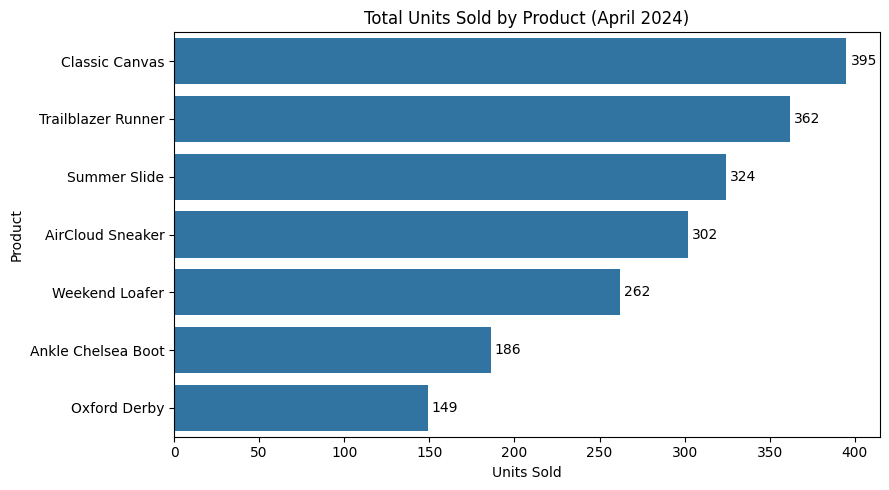

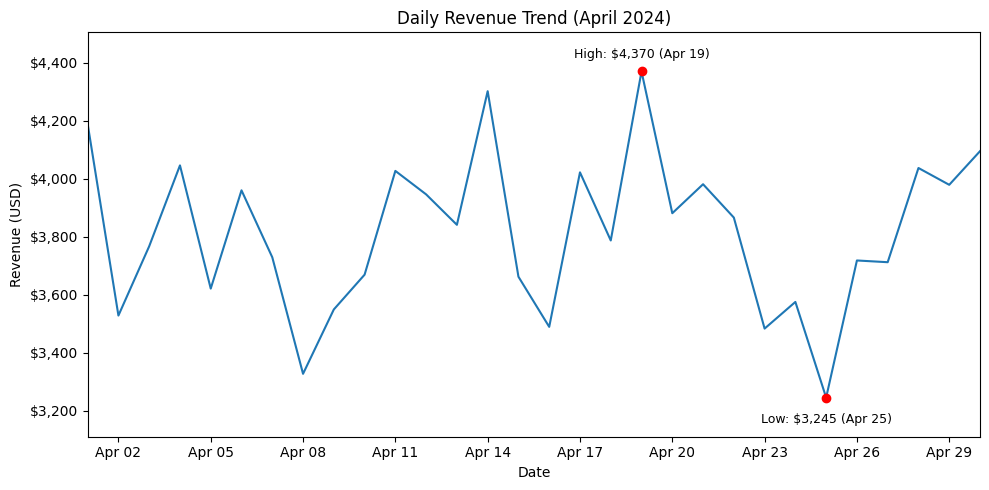

In [35]:
# Visualization
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns

# Chart 1: total quantity sold by product (bar)
# Bars follow the Q1 table order (most -> least sold).
fig, ax = plt.subplots(figsize=(9, 5))
sns.barplot(x=sold_quantity_by_product.values, y=sold_quantity_by_product.index, ax=ax)
ax.set_title('Total Units Sold by Product (April 2024)')
ax.set_xlabel('Units Sold')
ax.set_ylabel('Product')
ax.bar_label(ax.containers[0], padding=3)
plt.tight_layout()
plt.show()

# Chart 2: daily revenue trend across the month (line)
fig, ax = plt.subplots(figsize=(10, 5))
sns.lineplot(x='date', y='revenue', data=daily_total, ax=ax, errorbar=None)
ax.set_title('Daily Revenue Trend (April 2024)')
ax.set_xlabel('Date')
ax.set_ylabel('Revenue (USD)')
ax.yaxis.set_major_formatter('${x:,.0f}')
ax.set_xlim(daily_total['date'].min(), daily_total['date'].max())
ax.xaxis.set_major_locator(mdates.DayLocator(interval=3))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %d'))

# Mark the highest and lowest day so the exact values are on the chart
ax.margins(y=0.12)
for label, idx, dy in [('High', daily_total['revenue'].idxmax(), 10), ('Low', daily_total['revenue'].idxmin(), -18)]:
    row = daily_total.loc[idx]
    ax.scatter(row['date'], row['revenue'], color='red', zorder=3)
    ax.annotate(f"{label}: ${row['revenue']:,.0f} ({row['date']:%b %d})",
                (row['date'], row['revenue']), textcoords='offset points',
                xytext=(0, dy), ha='center', fontsize=9)
plt.tight_layout()
plt.show()


---
# 💼 Business Insights
*What did I discover?*

- Classic Canvas sold the most units (**395**), but Running earned the most revenue (**$46,360**).  
  (Classic Canvas가 판매량 1위(**395**개)지만, 매출 1위는 Running(**$46,360**)입니다.)  
- Oxford Derby sold the fewest units (**149**) and Sandals earned the least revenue (**$8,100**).  
  (Oxford Derby는 판매량이 가장 적고(**149**개), Sandals는 매출이 가장 낮습니다(**$8,100**).)  
- Daily revenue ranged from **$3,245** (Apr 25) to **$4,370** (Apr 19), a gap of **$1,125**.  
  (일별 매출은 **$3,245**(4/25)에서 **$4,370**(4/19) 사이였고, 차이는 **$1,125**입니다.)  
- Average daily revenue is highest on Sunday (**$4,012.25**) and lowest on Tuesday (**$3,628.80**).  
  (평균 일일 매출은 일요일이 가장 높고(**$4,012.25**) 화요일이 가장 낮습니다(**$3,628.80**).)  

---
# 🎯 Business Recommendation
*If I were the Business Analyst...*

1. Check whether Classic Canvas and Running are always in stock, since they lead units and revenue.  
   (판매량과 매출을 이끄는 Classic Canvas와 Running은 재고가 항상 있는지 확인합니다.)  
2. Review why Oxford Derby and Sandals sell little before cutting or promoting them.  
   (Oxford Derby와 Sandals가 적게 팔리는 이유를 먼저 살펴본 뒤 줄이거나 프로모션할지 정합니다.)  
3. Look into what drove the Apr 19 high and the Apr 25 low.  
   (4월 19일 최고점과 4월 25일 최저점의 원인을 살펴봅니다.)  

---
# ❌ Mistakes
*What mistakes did I make today?*

- I computed the daily average of product-level rows instead of the daily total first.  
  (하루 총매출을 먼저 만들지 않고 상품 행 단위로 평균을 냈습니다.)  
- I grouped the 30-row daily table by the 210-row `df` date column, so the rows were matched wrongly.  
  (30행 일별 표를 210행 `df`의 날짜 열로 묶어서 행이 잘못 맞춰졌습니다.)  
-   

---
# ✅ What I Learned
*Today's biggest lesson*

- Group by date first to get the daily total, then group by weekday to average the days.  
  (날짜별로 먼저 묶어 하루 총매출을 만든 뒤, 요일별로 묶어 평균을 냅니다.)  
- Use the columns of the same table when grouping, so the index aligns.  
  (묶을 때는 같은 표의 열을 써야 인덱스가 맞습니다.)  
-   

---
# 🧠 Reflection

**What was difficult?**



**Why?**



**How did I solve it?**



**What would I do differently next time?**



---
# ⭐ Self Evaluation

**Understanding**  
★★★★★★★★☆☆  
I understood the two-step groupby after working through the example.  
(예시로 풀어보며 2단계 groupby를 이해했습니다.)  

**Confidence**  
★★★★★★☆☆☆☆  

**Difficulty**  
★★★★★☆☆☆☆☆  

---
# 📌 Tomorrow
*Tomorrow I will learn:*

- Day 56: NumPy basics  
  (Day 56: NumPy 기초)  